<div style="border-left:7px solid #1A59FD; background:#F3F6FF; padding:16px 20px; border-radius:4px; font-family:Segoe UI, Arial, sans-serif;">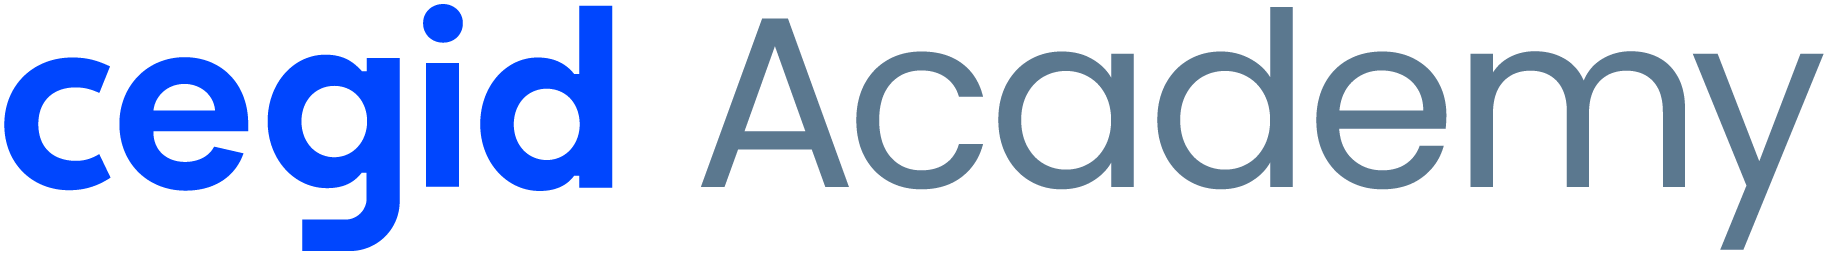<div style="font-size:22px; font-weight:700; color:#1A59FD; line-height:1.2;">Fase 5 &middot; Avaliação</div><div style="font-size:14px; color:#0A2540; margin-top:4px;">Implementação de Modelos Analíticos com Python &nbsp;&middot;&nbsp; Projeto CRISP-DM · <i>Evaluation</i> &nbsp;&middot;&nbsp; Versão <b>formandos</b> &nbsp;&middot;&nbsp; Apoio: <b>M5</b></div><div style="margin-top:10px;"><span style="display:inline-block;background:#D6E2FF;color:#1A59FD;border:1px solid #D6E2FF;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">1. Entendimento do Negócio</span><span style="display:inline-block;background:#D6E2FF;color:#1A59FD;border:1px solid #D6E2FF;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">2. Entendimento dos Dados</span><span style="display:inline-block;background:#D6E2FF;color:#1A59FD;border:1px solid #D6E2FF;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">3. Preparação dos Dados</span><span style="display:inline-block;background:#D6E2FF;color:#1A59FD;border:1px solid #D6E2FF;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">4. Modelação</span><span style="display:inline-block;background:#1A59FD;color:#FFFFFF;font-weight:600;border:1px solid #1A59FD;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">5. Avaliação</span><span style="display:inline-block;background:#FFFFFF;color:#0A2540;border:1px solid #C9D6F5;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">6. Deployment</span></div></div>

#### Identificação do projeto

| Campo | Preenchimento |
|---|---|
| **Projeto** | HR-Job-Change|
| **Grupo** |Grupo 3|
| **Formandos** |Cláudia Candeias - João Abreu |
| **Data** |18/10/2026 |
| **Dataset** |Dados_RH_Mudanca_Emprego.csv |

<div style="border-left:5px solid #1A59FD;background:#F3F6FF;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#1A59FD;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Objetivo</div>Verificar se o modelo <b>resolve o problema de negócio</b> definido na Fase 1. A Fase 4 respondeu a “qual o melhor modelo?”; esta fase responde a <b>“o modelo é útil — ou apenas estatisticamente bom?”</b><ul style="margin:4px 0 2px 0;"><li>Métricas técnicas face aos critérios de sucesso</li><li>Análise de erros</li><li>Importância das variáveis e interpretação</li><li>Limitações, conclusões e recomendações</li></ul></div>

### 0. Configuração
<hr>

**0.1 Bibliotecas** — base, `joblib`, validação cruzada, métricas, `DummyClassifier`/`DummyRegressor` e (complemento) `permutation_importance`.

In [1]:
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.inspection import permutation_importance

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

**0.2 Configuração** — ler `Data/output/config_projeto.json` (como no notebook 04).

In [2]:
with open("Data/output/config_projeto.json", encoding="utf-8") as f:
    config = json.load(f)

PROJETO = config["PROJETO"]
TARGET = config["TARGET"]
PROBLEM_TYPE = config["PROBLEM_TYPE"]
RANDOM_STATE = config["RANDOM_STATE"]
NUM_COLS = config["NUM_COLS"]
BIN_COLS = config["BIN_COLS"]
CAT_COLS = config["CAT_COLS"]
FEATURES = NUM_COLS + BIN_COLS + CAT_COLS
print(PROJETO, "|", PROBLEM_TYPE, "|", TARGET)

HR-Job-Change | classificacao | procura_mudanca_emprego


**0.3 Pastas** — as mesmas dos notebooks anteriores.

In [3]:
for pasta in ["Data/input", "Data/output", "Data/analytics", "Data/models"]:
    Path(pasta).mkdir(parents=True, exist_ok=True)

def guardar_figura(nome):
    caminho = Path("Data/analytics") / (nome + ".png")
    plt.savefig(caminho, dpi=150, bbox_inches="tight")
    print("Figura guardada em:", caminho)

**0.4 Carregar o modelo e os dados**
- `joblib.load` do modelo final, o `.json` de metadados, a tabela de comparação, e os dados de treino/teste (ou o dataset de clustering).
- Calcular as previsões no teste (`y_pred`) ou os clusters (`labels`).

In [4]:
modelo_final = joblib.load(f"Data/models/{PROJETO}_modelo_final.joblib")
with open(f"Data/models/{PROJETO}_modelo_final.json", encoding="utf-8") as f:
    info = json.load(f)
comparacao = pd.read_csv(f"Data/output/{PROJETO}_comparacao_modelos.csv", index_col="modelo")

train = pd.read_csv(f"Data/output/{PROJETO}_train.csv", index_col="id_candidato")
test = pd.read_csv(f"Data/output/{PROJETO}_test.csv", index_col="id_candidato")
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

y_pred = modelo_final.predict(X_test)
y_prob = modelo_final.predict_proba(X_test)[:, 1]

print("Modelo:", info["modelo"])
print(X_train.shape, X_test.shape)
comparacao[["f1_cv_media", "f1_cv_desvio", "recall_cv", "f1_teste", "recall_teste"]].round(3)

Modelo: Random Forest (Random)
(15326, 14) (3832, 14)


,f1_cv_media,f1_cv_desvio,recall_cv,f1_teste,recall_teste
modelo,,,,,
Random Forest (Random),0.638,0.007,0.745,0.613,0.715
Random Forest (Grid),0.628,0.008,0.750,0.616,0.733
Decision Tree (Grid),0.623,0.011,0.740,0.596,0.723
Logistic Regression (Grid),0.590,0.008,0.762,0.571,0.732
Logistic Regression,0.589,0.008,0.761,0.570,0.732
Random Forest,0.586,0.014,0.629,0.566,0.612
KNN (Grid),0.461,0.014,0.392,0.437,0.371
KNN,0.452,0.015,0.393,0.443,0.384
Decision Tree,0.447,0.006,0.445,0.440,0.449


### 1. Relembrar o problema de negócio
<hr>

- Qual era o problema inicial e que decisão se pretende apoiar? (Fase 1, secções 2 e 3)
- Qual a métrica principal e qual o critério de sucesso definido?

**Objetivo:** garantir alinhamento com o problema de negócio.

**Resposta:**

- **Problema:** uma entidade de recrutamento quer identificar, entre os candidatos que fizeram uma formação, os que procuram mudar de emprego, para concentrar os contactos em quem está recetivo em vez de contactar toda a gente (Fase 1, secção 2).
- **Decisão a apoiar:** a que candidatos fazer uma proposta de trabalho; a decisão é dos RH/recrutamento.
- **Métrica principal:** recall da classe "Sim" (falhar um candidato recetivo é pior do que fazer um contacto a mais), com o F1 a impedir que o recall suba só porque se prevê "Sim" para todos.
- **Critério de sucesso:** Recall (Sim) ≥ 0,70 e F1 (Sim) ≥ 0,55, superar o baseline que prevê sempre "Não", identificar as 3 variáveis mais influentes e responder às questões Q1–Q4.

### 2. Resultados face aos critérios de sucesso
<hr>

Preencher a tabela com os critérios da **Fase 1 (secção 7)** e os valores obtidos.

| Critério (Fase 1) | Meta | Resultado obtido (teste, limiar 0,55) | Cumprido? |
|---|---|---|---|
| Recall (Sim) | ≥ 0,70 | 0,705 (0,715 com limiar 0,5) | Sim (à justa) |
| F1 (Sim) | ≥ 0,55 | 0,617 | Sim |
| Superar o baseline | Melhor do que prever sempre "Não" (recall 0, F1 0, accuracy 0,751) | Recall 0,705, F1 0,617, accuracy 0,782 | Sim |
| Interpretabilidade | Identificar as 3 variáveis mais influentes | Índice de desenvolvimento da cidade, dados da empresa em falta (`dimensao_empresa`/`tipo_empresa`), nível de educação (secção 6) | Sim |
| Resposta às questões de negócio | Q1–Q4 com evidência | Ver tabela da secção 8 | Sim |

**2.1 [Classificação] Métricas do modelo final no teste**
- Accuracy, precision, recall, F1 e ROC-AUC.

In [5]:
def metricas(y, y_pred, y_prob):
    return {
        "accuracy": accuracy_score(y, y_pred),
        "precision": precision_score(y, y_pred, zero_division=0),
        "recall": recall_score(y, y_pred),
        "f1": f1_score(y, y_pred),
        "roc_auc": roc_auc_score(y, y_prob),
    }

pd.Series(metricas(y_test, y_pred, y_prob), name="teste (limiar 0,5)").round(3)

accuracy     0.775
precision    0.536
recall       0.715
f1           0.613
roc_auc      0.792
Name: teste (limiar 0,5), dtype: float64

##### Análise e Interpretação

> *Os critérios de sucesso da Fase 1 foram atingidos? Preencham a tabela acima.*

**Resposta:**

- Com o limiar por defeito (0,5), o modelo já cumpre as duas metas de desempenho no teste: **recall 0,715** (≥ 0,70) e **F1 0,613** (≥ 0,55). O ROC-AUC é 0,792 e a accuracy 0,775.
- Com o limiar escolhido na secção 4.3 (**0,55**, escolhido com a CV no treino), o resultado final é **recall 0,705, F1 0,617, precision 0,548**: continua a cumprir as metas, com menos falsos positivos. Estes são os valores que pusemos na tabela acima.
- A precision (0,55) é a parte mais fraca: cerca de metade dos contactados não estão à procura. Mesmo assim é mais do dobro da taxa de "Sim" ao acaso (25%).

<hr>

### 3. Análise de overfitting / underfitting e robustez
<hr>

- Existe grande diferença entre treino, validação cruzada e teste?
- O modelo é demasiado simples (underfitting) ou demasiado complexo (overfitting)?
- É **robusto** a pequenas variações dos dados? (desvio padrão na validação cruzada)

**3.1 [Classificação] Treino vs validação cruzada vs teste**
- Para accuracy e F1: score no treino, média e desvio da CV (treino) e score no teste; diagnóstico (treino − teste > 0,10).

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
r = cross_validate(modelo_final, X_train, y_train, cv=cv, scoring=["accuracy", "f1"], n_jobs=-1)
y_pred_treino = modelo_final.predict(X_train)

linhas = []
for nome, func in [("accuracy", accuracy_score), ("f1", f1_score)]:
    treino = func(y_train, y_pred_treino)
    teste = func(y_test, y_pred)
    linhas.append([nome, treino, r["test_" + nome].mean(), r["test_" + nome].std(), teste, treino - teste])

diag = pd.DataFrame(linhas, columns=["metrica", "treino", "cv_media", "cv_desvio", "teste", "treino - teste"]).set_index("metrica")
diag["diagnostico"] = np.where(diag["treino - teste"] > 0.10, "overfitting", "ok")
diag.round(3)

,treino,cv_media,cv_desvio,teste,treino - teste,diagnostico
metrica,,,,,,
accuracy,0.799,0.789,0.005,0.775,0.025,ok
f1,0.655,0.638,0.007,0.613,0.042,ok


##### Análise e Interpretação

> *O modelo generaliza bem? É estável entre folds?*

**Resposta:**

- **Generaliza bem:** a accuracy passa de 0,799 no treino para 0,789 na CV e 0,775 no teste; o F1 de 0,655 para 0,638 e 0,613. A diferença treino−teste é 0,025 na accuracy e 0,042 no F1, muito abaixo dos 0,10, por isso não há overfitting.
- **É estável:** o desvio entre os 5 folds é muito pequeno (0,005 na accuracy e 0,007 no F1), por isso pequenas mudanças nos dados de treino quase não mudam o resultado.
- Também não há underfitting: o F1 no treino não está "preso" num valor baixo e o modelo supera claramente modelos mais simples (logística 0,590 na CV). As folhas com pelo menos 20 candidatos (`min_samples_leaf=20`) foram o que tirou o overfitting da Random Forest original (0,99 no treino).

<hr>

### 4. Análise de erros
<hr>

**Classificação:** matriz de confusão (valores e percentagens), falsos positivos vs falsos negativos e o seu **custo para o negócio**, classes ou segmentos mais difíceis de prever.

**Regressão:** resíduos, erro por faixa de valores do target, maiores erros, erro por segmento.

**Objetivo:** compreender **onde e porquê** o modelo falha.

**4.1 [Classificação] Matriz de confusão**
- Em valores absolutos e normalizada por classe real (`normalize="true"`); em binário, contar VP, VN, FP e FN; `classification_report`.

Figura guardada em: Data\analytics\05-4.1-matriz_confusao_avaliacao.png


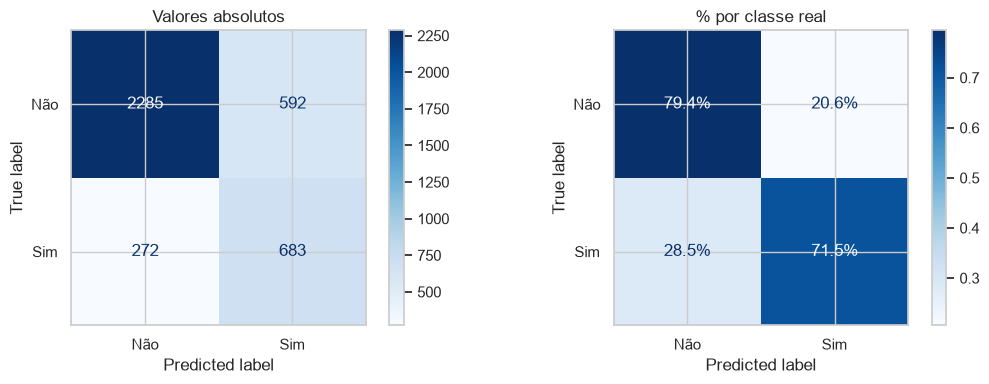

VP: 683 | VN: 2285 | FP: 592 | FN: 272
              precision    recall  f1-score   support

         Não      0.894     0.794     0.841      2877
         Sim      0.536     0.715     0.613       955

    accuracy                          0.775      3832
   macro avg      0.715     0.755     0.727      3832
weighted avg      0.804     0.775     0.784      3832



In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Não", "Sim"], cmap="Blues", ax=axes[0])
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Não", "Sim"], cmap="Blues",
                                        normalize="true", values_format=".1%", ax=axes[1])
axes[0].set_title("Valores absolutos")
axes[1].set_title("% por classe real")
plt.tight_layout()
guardar_figura("05-4.1-matriz_confusao_avaliacao")
plt.show()

vn, fp, fn, vp = confusion_matrix(y_test, y_pred).ravel()
print("VP:", vp, "| VN:", vn, "| FP:", fp, "| FN:", fn)
print(classification_report(y_test, y_pred, target_names=["Não", "Sim"], digits=3))

##### Análise e Interpretação

> *Que classe é mais difícil de prever? Quantos falsos positivos e falsos negativos há e quanto custa cada um ao negócio?*

**Resposta:**

- **A classe mais difícil é "Sim"** (precision 0,536, F1 0,613), contra F1 0,841 na classe "Não". É a classe minoritária e a que se sobrepõe mais com a outra (já se via na Fase 2).
- Com o limiar 0,5: **683 VP, 2 285 VN, 592 FP e 272 FN**. Em percentagem da classe real, o modelo apanha 71,5% dos que procuram mudar e deixa escapar 28,5%; dos que não procuram, 20,6% são marcados como "Sim" por engano.
- **Custo para o negócio:**
  - **FN (272):** candidatos que estão à procura e não são contactados. É uma oportunidade perdida e pode ir para a concorrência. É o erro mais caro.
  - **FP (592):** contactos feitos a quem não está interessado. Custa tempo de um recrutador (uma chamada/email), mas é barato e reversível.
- O modelo erra mais por FP (592) do que por FN (272), como queríamos: com o `class_weight="balanced"` troca falsos negativos por falsos positivos, que são os erros mais baratos.

<hr>

**4.2 [Classificação] Erros por segmento**
- Criar uma coluna `erro` (real ≠ previsto) no teste e calcular a taxa de erro por categoria; listar alguns casos mal classificados.

In [8]:
teste = X_test.copy()
teste["real"] = y_test
teste["previsto"] = y_pred
teste["prob_sim"] = y_prob.round(3)
teste["erro"] = (teste["real"] != teste["previsto"]).astype(int)

for col in ["genero", "experiencia_relevante", "empresa_em_falta", "nivel_educacao", "tipo_empresa"]:
    seg = teste.assign(**{col: teste[col].fillna("Em falta")})
    tabela = seg.groupby(col).agg(n=("erro", "size"), taxa_erro=("erro", "mean"), pct_sim_real=("real", "mean"))
    # recall dentro de cada grupo: dos que procuram mesmo mudar, quantos apanhámos
    tabela["recall"] = seg[seg["real"] == 1].groupby(col)["previsto"].mean()
    print(f"\n--- {col} ---")
    print(tabela.round(3))


--- genero ---
              n  taxa_erro  pct_sim_real  recall
genero                                          
Em falta    924      0.277         0.306   0.774
Feminino    252      0.222         0.246   0.790
Masculino  2623      0.207         0.230   0.684
Outro        33      0.242         0.182   0.333

--- experiencia_relevante ---
                              n  taxa_erro  pct_sim_real  recall
experiencia_relevante                                           
Com experiência relevante  2746      0.193         0.222   0.660
Sem experiência relevante  1086      0.307         0.319   0.812

--- empresa_em_falta ---
                     n  taxa_erro  pct_sim_real  recall
empresa_em_falta                                       
0                 2504      0.156         0.186   0.569
1                 1328      0.356         0.368   0.855

--- nivel_educacao ---
                      n  taxa_erro  pct_sim_real  recall
nivel_educacao                                          
Doutorament

##### Análise e Interpretação

> *Há segmentos onde o modelo erra muito mais? Porquê?*

**Resposta:**

- **Sim, o modelo erra muito mais nos candidatos sem dados da empresa** (`empresa_em_falta` = 1, ou `tipo_empresa` em falta): taxa de erro de 0,356–0,360 contra 0,156–0,162 nos que têm dados. Nestes grupos a taxa real de "Sim" é alta (~37%) e o modelo marca muita gente como "Sim": o recall é ótimo (0,855–0,867), mas há muitos falsos positivos. "Não ter dados da empresa" é um sinal forte, mas junta perfis muito diferentes (desempregados, estudantes, quem não respondeu).
- **Sem experiência relevante:** mais erro (0,307 vs 0,193), pelo mesmo motivo: grupo com mais "Sim" (32%) e mais heterogéneo.
- **Nos grupos com pouca procura** (Ensino Básico, Doutoramento, Setor público, "Outro" em `tipo_empresa`), a taxa de erro é baixa, mas o **recall é muito fraco** (0,20–0,39): os poucos "Sim" destes grupos quase não são encontrados, porque o modelo aprendeu que "normalmente não procuram". Atenção: são grupos pequenos (28 a 173 candidatos).
- **Género (Q4):** a taxa de erro é parecida entre Masculino (0,207) e Feminino (0,222), mas o recall não: **0,684 nos homens contra 0,790 nas mulheres** (e 0,774 sem género indicado). Os homens que procuram mudar são um pouco menos encontrados e ficam ligeiramente abaixo da meta de 0,70. "Outro" tem só 33 candidatos (6 "Sim"), demasiado pouco para concluir.
- **Porquê:** o modelo depende muito do índice da cidade e dos dados em falta; nos grupos em que estes sinais não aparecem (empresa conhecida, cidade desenvolvida), os candidatos que procuram mudar ficam "escondidos".

<hr>

#### 4.1 (Complemento) Ajuste do limiar de decisão — classificação binária

Por defeito, o modelo prevê a classe positiva quando a probabilidade ≥ 0,5. Baixar o limiar aumenta o **recall** (menos falsos negativos) à custa da **precision**; subir faz o contrário. É o mesmo compromisso que se vê na curva ROC / Precision-Recall — a escolha depende do **custo de cada erro** no negócio.

O limiar é um hiperparâmetro: escolhê-lo a olhar para o teste é *data leakage* (o resultado reportado fica otimista). Escolhe-se com probabilidades obtidas por validação cruzada no treino e só depois se aplica ao teste.

<div style="border-left:5px solid #6B7A90;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#6B7A90;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Complemento (não dado em aula)</div>O ajuste do limiar não foi dado em aula. É uma extensão natural da curva ROC (M5): cada ponto da curva corresponde a um limiar diferente.</div>

**4.3 (Complemento) Ajuste do limiar de decisão**
- Obter probabilidades fora da amostra **no treino**: `cross_val_predict(modelo_final, X_train, y_train, cv=..., method="predict_proba")`.
- Para limiares de 0,2 a 0,8, calcular precision, recall e F1 sobre essas probabilidades e desenhar as três curvas.
- Escolher o limiar e só então aplicá-lo, **uma vez**, às probabilidades do teste para reportar o resultado.

Figura guardada em: Data\analytics\05-4.3-ajuste_limiar.png


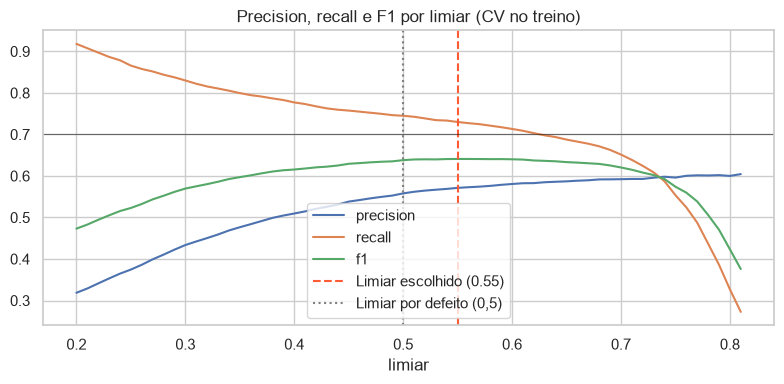

Limiar escolhido: 0.55
        precision  recall     f1
limiar                          
0.50        0.558   0.745  0.638
0.55        0.571   0.730  0.641
0.62        0.583   0.703  0.637


,"limiar 0,5",limiar 0.55
accuracy,0.775,0.782
precision,0.536,0.548
recall,0.715,0.705
f1,0.613,0.617
roc_auc,0.792,0.792


In [13]:
# probabilidades fora da amostra no treino: cada candidato é previsto por um modelo que não o viu
prob_cv = cross_val_predict(modelo_final, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]

limiares = np.round(np.arange(0.20, 0.81, 0.01), 2)
curvas = pd.DataFrame([[l, precision_score(y_train, prob_cv >= l), recall_score(y_train, prob_cv >= l), f1_score(y_train, prob_cv >= l)]
                       for l in limiares], columns=["limiar", "precision", "recall", "f1"]).set_index("limiar")

# entre os limiares com recall >= 0,70 no treino (critério da Fase 1), o que dá melhor F1
validos = curvas[curvas["recall"] >= 0.70]
LIMIAR = validos["f1"].idxmax()
limiar_max = validos.index.max()  # o mais alto que ainda chega aos 0,70 (fica mesmo no limite)

ax = curvas.plot(figsize=(8, 4))
ax.axvline(LIMIAR, color="#FF5B34", linestyle="--", label=f"Limiar escolhido ({LIMIAR})")
ax.axvline(0.5, color="grey", linestyle=":", label="Limiar por defeito (0,5)")
ax.axhline(0.70, color="black", linewidth=0.8, alpha=0.5)
ax.set_title("Precision, recall e F1 por limiar (CV no treino)")
ax.legend()
plt.tight_layout()
guardar_figura("05-4.3-ajuste_limiar")
plt.show()

print("Limiar escolhido:", LIMIAR)
print(curvas.loc[sorted({0.5, LIMIAR, limiar_max})].round(3))


# só agora aplicamos ao teste, uma vez
y_pred_limiar = (y_prob >= LIMIAR).astype(int)

info["limiar_decisao"] = float(LIMIAR)
with open(f"Data/models/{PROJETO}_modelo_final.json", "w", encoding="utf-8") as f:
    json.dump(info, f, ensure_ascii=False, indent=2)

pd.DataFrame({"limiar 0,5": metricas(y_test, y_pred, y_prob),
              f"limiar {LIMIAR}": metricas(y_test, y_pred_limiar, y_prob)}).round(3)

##### Análise e Interpretação

> *Que limiar escolheriam tendo em conta o custo de cada tipo de erro?*

**Resposta:**

- As probabilidades foram obtidas com `cross_val_predict` no treino (cada candidato previsto por um modelo que não o viu), por isso o teste não entrou na escolha.
- No gráfico, o F1 quase não muda entre 0,50 e 0,62 (0,637–0,641): nesta zona o limiar mexe sobretudo na troca entre recall e precision. Para limiares baixos o recall sobe mas a precision cai; acima de 0,62 o recall fica abaixo da meta.
- **Limiar escolhido: 0,55**, o que dá o melhor F1 na CV (0,641) entre os limiares com recall ≥ 0,70 (CV: recall 0,730, precision 0,571). Tem em conta o custo dos erros: mantém o recall acima da meta (o FN é o erro caro) e, em troca, corta alguns contactos inúteis face ao 0,5.
- **Aplicado uma única vez ao teste:** recall 0,705, precision 0,548, F1 0,617 (vs 0,715 / 0,536 / 0,613 com 0,5). São menos 47 candidatos contactados (1 228 vs 1 275) com quase o mesmo número de candidatos recetivos encontrados.
- **Nota (transparência):** a primeira regra que usámos foi "o limiar mais alto com recall ≥ 0,70 na CV", que deu 0,62. Ao aplicá-lo ao teste, o recall caiu para 0,686, abaixo da meta, porque esse limiar fica mesmo no limite na CV. Trocámos para a regra do melhor F1 com recall ≥ 0,70, que deixa margem. Como esta troca foi feita depois de ver o teste, fica registada como limitação (secção 7).
- Para os RH, o limiar é uma alavanca: se houver poucos recrutadores, pode subir-se (menos contactos, mais precisos); se o importante for não perder ninguém, pode baixar-se.

<hr>

### 5. Comparação com o baseline
<hr>

O modelo supera uma abordagem simples (prever sempre a classe maioritária / a média histórica)? Em quanto?

**Objetivo:** demonstrar valor acrescentado.

**5.1 [Classificação] Comparação com o baseline**
- `DummyClassifier(strategy="most_frequent")` vs modelo final: accuracy e F1 no teste.

In [10]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
y_dummy = dummy.predict(X_test)

linhas = []
for nome, prev in [("Baseline (sempre Não)", y_dummy), (f"{info['modelo']} (limiar 0,5)", y_pred),
                   (f"{info['modelo']} (limiar {LIMIAR})", y_pred_limiar)]:
    linhas.append([nome, accuracy_score(y_test, prev), precision_score(y_test, prev, zero_division=0),
                   recall_score(y_test, prev), f1_score(y_test, prev), prev.sum()])

pd.DataFrame(linhas, columns=["modelo", "accuracy", "precision", "recall", "f1", "n_previstos_sim"]).set_index("modelo").round(3)

,accuracy,precision,recall,f1,n_previstos_sim
modelo,,,,,
Baseline (sempre Não),0.751,0.000,0.000,0.000,0
"Random Forest (Random) (limiar 0,5)",0.775,0.536,0.715,0.613,1275
Random Forest (Random) (limiar 0.55),0.782,0.548,0.705,0.617,1228


##### Análise e Interpretação

> *Quanto valor acrescenta o modelo face a prever sempre a classe maioritária?*

**Resposta:**

- O baseline (prever sempre "Não") tem **accuracy 0,751, mas recall e F1 = 0**: não encontra nenhum candidato recetivo, por isso não serve para a decisão.
- O modelo final (limiar 0,55) tem **accuracy 0,782 (+3,1 p.p.), recall 0,705 e F1 0,617**: encontra 673 dos 955 candidatos que procuram mudar.
- Em termos de negócio: se os RH contactassem 1 228 candidatos ao acaso, encontrariam ~306 recetivos (25%); com o modelo encontram 673, mais do dobro com o mesmo esforço (precision 0,548 vs 0,249).
- A melhoria na accuracy é pequena porque a accuracy é dominada pela classe "Não"; o valor do modelo está no recall e no F1.

<hr>

### 6. Importância das variáveis e interpretação
<hr>

Que variáveis mais influenciam as previsões? Confirmam as hipóteses da Fase 1 e a análise da Fase 2?

| Modelo | Como interpretar |
|---|---|
| Decision Tree, Random Forest | `feature_importances_` — contributo de cada variável para as divisões (visto no M3.02, na seleção de variáveis) |
| Logistic / Linear Regression | `coef_` — sinal (aumenta/diminui) e magnitude (com variáveis escalonadas) |
| Qualquer modelo (inclusive KNN) | **Permutation importance** (complemento) — quanto piora o modelo quando se baralha a variável |
| K-Means | perfil dos clusters (médias por cluster) — ver Fase 4, secção 4.3 |

**6.1 Importância das variáveis**
- Nomes das variáveis após a preparação: `modelo_final.named_steps["prep"].get_feature_names_out()`.
- Árvores: `feature_importances_`; modelos lineares: `coef_`. Gráfico de barras das 15 mais importantes.

Figura guardada em: Data\analytics\05-6.1-importancia_variaveis.png


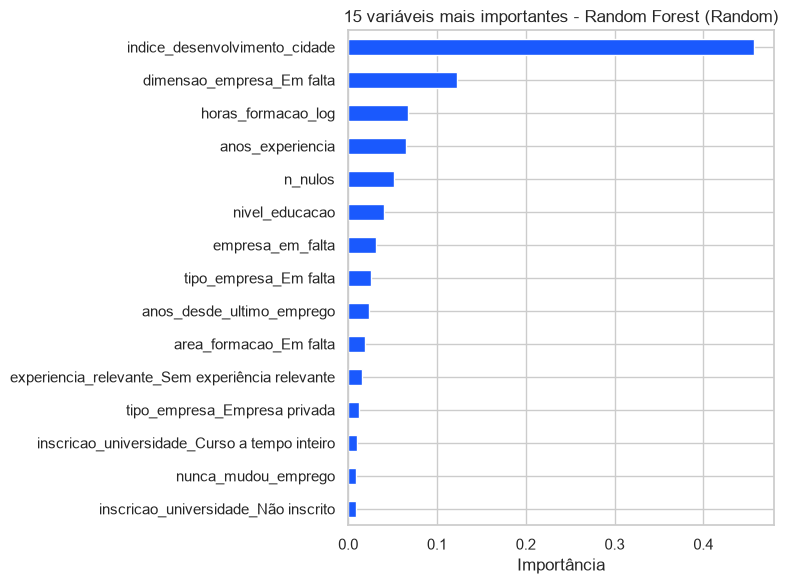

indice_desenvolvimento_cidade                      0.4567
dimensao_empresa_Em falta                          0.1228
horas_formacao_log                                 0.0671
anos_experiencia                                   0.0649
n_nulos                                            0.0513
nivel_educacao                                     0.0400
empresa_em_falta                                   0.0318
tipo_empresa_Em falta                              0.0252
anos_desde_ultimo_emprego                          0.0238
area_formacao_Em falta                             0.0188
experiencia_relevante_Sem experiência relevante    0.0161
tipo_empresa_Empresa privada                       0.0122
inscricao_universidade_Curso a tempo inteiro       0.0095
nunca_mudou_emprego                                0.0092
inscricao_universidade_Não inscrito                0.0088
dtype: float64

In [11]:
clf = modelo_final.named_steps["clf"]
nomes = modelo_final.named_steps["prep"].get_feature_names_out()

if hasattr(clf, "feature_importances_"):
    importancia = pd.Series(clf.feature_importances_, index=nomes)
else:  # modelos lineares: coeficientes (as numéricas estão escalonadas)
    importancia = pd.Series(clf.coef_[0], index=nomes)

top15 = importancia.reindex(importancia.abs().sort_values(ascending=False).index).head(15)

plt.figure(figsize=(8, 6))
top15[::-1].plot(kind="barh", color="#1A59FD")
plt.title(f"15 variáveis mais importantes - {info['modelo']}")
plt.xlabel("Importância")
plt.tight_layout()
guardar_figura("05-6.1-importancia_variaveis")
plt.show()

top15.round(4)

##### Análise e Interpretação

> *Que variáveis mais influenciam as previsões? Confirmam as hipóteses da Fase 1?*

**Resposta:**

- **Variável mais importante, de longe: `indice_desenvolvimento_cidade`** (0,457 da importância total). Confirma a **H2**: candidatos de cidades menos desenvolvidas procuram mais mudar.
- **2.º: `dimensao_empresa_Em falta`** (0,123), mais `n_nulos` (0,051), `empresa_em_falta` (0,032), `tipo_empresa_Em falta` (0,025) e `area_formacao_Em falta` (0,019). Somadas, as variáveis de dados em falta são o segundo grande bloco. Confirma a **H6** (a falta de dados da empresa está associada à procura).
- **Experiência:** `anos_experiencia` (0,065) e `experiencia_relevante_Sem experiência relevante` (0,016) aparecem no top 15. Confirmam **H4** e **H1**, mas com peso bem menor do que na Fase 2 (parte da informação já está nas colunas "Em falta").
- **`horas_formacao_log`** aparece em 3.º (0,067), mas a importância das árvores favorece variáveis contínuas com muitos pontos de corte (já visto na Fase 3, secção 9.3); a permutation importance (6.2) mostra que na prática quase não ajuda, por isso a **H3** não se confirma.
- **H5 (tipo/dimensão da empresa):** confirmada sobretudo pela categoria "Em falta"; as categorias concretas (`tipo_empresa_Empresa privada`, por exemplo) têm pouco peso.
- **As 3 variáveis mais influentes** (critério da Fase 1): índice de desenvolvimento da cidade, falta de dados da empresa (dimensão/tipo) e nível de educação/experiência (ver 6.2 para a ordem nas variáveis originais).

<hr>

<div style="border-left:5px solid #6B7A90;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#6B7A90;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Complemento (não dado em aula)</div>A <b>permutation importance</b> funciona com qualquer modelo e mede a importância nas variáveis <b>originais</b> (antes do One-Hot Encoding), o que facilita a comunicação dos resultados ao negócio.</div>

**6.2 (Complemento) Permutation importance**
- `permutation_importance(modelo_final, X_test, y_test, n_repeats=10)` e gráfico por variável original.

Figura guardada em: Data\analytics\05-6.2-permutation_importance.png


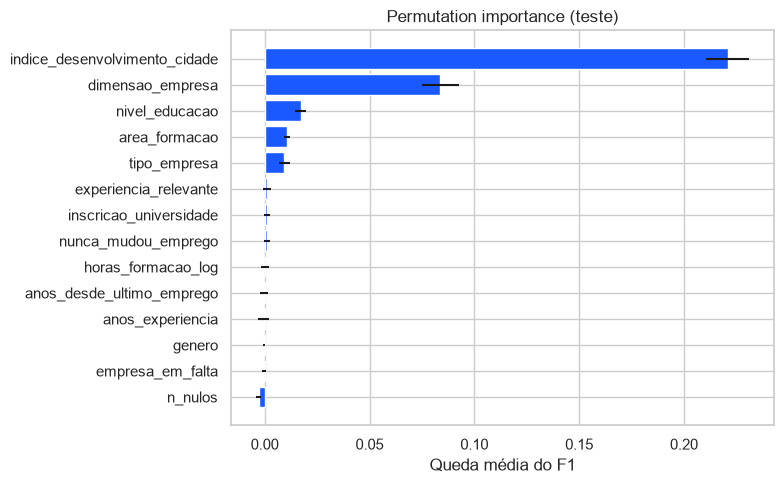

,queda_f1,desvio
indice_desenvolvimento_cidade,0.2209,0.0103
dimensao_empresa,0.0838,0.0087
nivel_educacao,0.0172,0.0026
area_formacao,0.0109,0.0014
tipo_empresa,0.0093,0.0026
experiencia_relevante,0.0011,0.0017
inscricao_universidade,0.0010,0.0013
nunca_mudou_emprego,0.0010,0.0013
horas_formacao_log,-0.0001,0.0019
anos_desde_ultimo_emprego,-0.0003,0.0018


In [12]:
# baralha cada variável original e vê quanto cai o F1 no teste
perm = permutation_importance(modelo_final, X_test, y_test, scoring="f1", n_repeats=10,
                              random_state=RANDOM_STATE, n_jobs=-1)
perm_imp = pd.DataFrame({"queda_f1": perm.importances_mean, "desvio": perm.importances_std},
                        index=X_test.columns).sort_values("queda_f1", ascending=False)

plt.figure(figsize=(8, 5))
plt.barh(perm_imp.index[::-1], perm_imp["queda_f1"][::-1], xerr=perm_imp["desvio"][::-1], color="#1A59FD")
plt.title("Permutation importance (teste)")
plt.xlabel("Queda média do F1")
plt.tight_layout()
guardar_figura("05-6.2-permutation_importance")
plt.show()

perm_imp.round(4)

##### Análise e Interpretação

> *Os resultados coincidem com a importância nativa do modelo?*

**Resposta:**

- **Em parte.** As duas primeiras coincidem: `indice_desenvolvimento_cidade` (queda de 0,221 no F1 quando é baralhada) e `dimensao_empresa` (0,084) são, de longe, as mais importantes nos dois métodos.
- Depois vêm `nivel_educacao` (0,017), `area_formacao` (0,011) e `tipo_empresa` (0,009). Todas as outras ficam perto de 0.
- **Diferenças:**
  - `horas_formacao_log` e `anos_experiencia` tinham importância nativa alta (~0,065), mas na permutation ficam em ~0. A importância nativa sobrevaloriza as contínuas; na prática o modelo quase não perde nada sem elas.
  - `n_nulos` e `empresa_em_falta` ficam a 0 ou ligeiramente negativas: a informação deles também está em `dimensao_empresa`/`tipo_empresa` ("Em falta"). Quando baralhamos uma, o modelo usa as outras. Não quer dizer que a falta de dados não importa, quer dizer que está repetida em várias colunas.
- **`genero` tem importância ~0 (-0,0005):** o modelo praticamente não usa o género, o que é bom do ponto de vista ético (Q4). As diferenças de recall da secção 4.2 vêm de outras variáveis associadas ao género, não do género em si.
- Para comunicar ao negócio, a permutation importance é mais clara: **a cidade e a falta de informação sobre a empresa atual explicam quase tudo**.

<hr>

### 7. Limitações do modelo
<hr>

- **Dados:** dimensão da amostra, período coberto, representatividade, qualidade
- **Modelo:** pressupostos, interpretabilidade, sensibilidade a outliers, estabilidade
- **Validação:** houve decisões tomadas depois de ver o teste? Há passos fora do Pipeline (seleção de variáveis, target encoding, capping) que tornam a CV otimista? Ficou algum risco de *data leakage* por resolver?
- **Viés e ética:** o modelo usa variáveis sensíveis (género, idade, estado civil)? Pode discriminar grupos? É aceitável usá-las na decisão?

**Objetivo:** reconhecer fragilidades.

**Resposta:**

**Dados**
- Só temos um retrato "do momento" de 19 158 candidatos que fizeram uma formação; não há histórico nem datas. Os resultados não se podem generalizar para a população em geral (Fase 1).
- Muitos valores em falta (53% das linhas têm pelo menos um nulo) e o modelo depende muito deles. Se a forma de recolher os dados mudar (por exemplo, o formulário passar a obrigar a indicar a empresa), o modelo pode deixar de funcionar bem.
- A `cidade` foi removida (Fase 3) e com ela perdem-se diferenças entre cidades com o mesmo índice.
- Valores atribuídos por convenção ("Mais de 20 anos" → 21, "Nunca" → 0...).

**Modelo**
- A precision é modesta (0,55): cerca de metade dos contactos são para quem não está à procura.
- Uma Random Forest com 230 árvores não dá regras simples; a interpretação é feita pela importância das variáveis, que mostra o que pesa, mas não explica cada previsão.
- Depende quase só de duas variáveis (índice da cidade e dados em falta da empresa); nos grupos onde estes sinais não aparecem, o recall é baixo (secção 4.2).

**Validação**
- **O limiar foi alterado depois de ver o teste:** a primeira regra (limiar 0,62) dava recall 0,686 no teste; trocámos para a regra do melhor F1 com recall ≥ 0,70 na CV (limiar 0,55). Os valores finais no teste (recall 0,705, F1 0,617) são por isso ligeiramente otimistas; o mais honesto é esperar um recall à volta de 0,69–0,71 em dados novos.
- A seleção de variáveis da Fase 3 (secção 9.3) foi feita com o treino completo. Como não removeu nenhuma variável, o impacto na CV é mínimo.
- O preprocessador ficou todo dentro do Pipeline (ajustado em cada fold); os passos fora do Pipeline (`criar_features`, conversão dos anos) são regras fixas, sem leakage.
- Escolher o melhor entre 10 candidatos pela CV dá sempre algum otimismo (F1 0,638 na CV vs 0,613 no teste).

**Viés e ética**
- O dataset tem `genero`, uma variável sensível. O modelo quase não a usa (permutation importance ≈ 0), mas o recall é diferente entre grupos: 0,684 nos homens contra 0,790 nas mulheres. Não é uma discriminação contra as mulheres (são até mais encontradas), mas mostra que o modelo não trata todos os grupos da mesma forma.
- Como o género não ajuda o modelo, a recomendação é retirá-lo numa próxima versão e não o usar na decisão.
- O índice da cidade pode funcionar como um indicador indireto de nível socioeconómico: o modelo vai sempre dar prioridade a candidatos de cidades menos desenvolvidas, e isso deve ser uma escolha consciente dos RH.

### 8. Conclusões e recomendações
<hr>

- Resposta a cada **questão de negócio** da Fase 1 (Q1, Q2, Q3…), com evidência
- Principais fatores que explicam o fenómeno
- **Recomendações concretas** para a entidade (ex.: estratégias para melhorar a retenção)

| Questão de negócio | Resposta | Evidência (gráfico / métrica) |
|---|---|---|
| Q1 - É possível prever, pelo perfil, se o candidato procura mudar? | Sim, com um desempenho razoável: o modelo encontra ~70% dos candidatos que procuram mudar e, dos que marca como "Sim", ~55% estão mesmo à procura (o dobro do acaso) | Recall 0,705, F1 0,617, ROC-AUC 0,792 no teste; CV F1 0,638 ± 0,007 (secções 2, 3 e 5) |
| Q2 - Que características se associam à procura? | Sobretudo viver numa cidade menos desenvolvida e não ter dados sobre a empresa atual; depois o nível de educação (Licenciatura procura mais) e a área de formação. Experiência e horas de formação pesam pouco depois de juntar estas | Importância nativa e permutation importance (secção 6; `importancia_variaveis.png`, `permutation_importance.png`) |
| Q3 - Os valores em falta estão associados à procura? | Sim, é a segunda informação mais útil: quem não tem dados da empresa tem ~37% de "Sim" contra ~19%, e as colunas "Em falta" estão no topo da importância | `dimensao_empresa_Em falta` 0,123 na importância; `dimensao_empresa` 0,084 na permutation; taxa de "Sim" por `empresa_em_falta` (secção 4.2) |
| Q4 - O modelo é equilibrado entre géneros? | Em parte: o modelo quase não usa o género e a taxa de erro é parecida (0,21 vs 0,22), mas o recall é mais baixo nos homens (0,684) do que nas mulheres (0,790) | Erros por segmento (secção 4.2); permutation importance de `genero` ≈ 0 (secção 6.2) |

**Principais fatores:** o contexto geográfico (índice de desenvolvimento da cidade) e a situação profissional desconhecida ou instável (sem dados da empresa) explicam a maior parte da procura de mudança. O perfil académico vem a seguir.

**Recomendações:**

- **Usar o modelo para ordenar os candidatos**, não para decidir por eles: os RH começam pelos candidatos com maior probabilidade (o ficheiro `Results.csv` da Fase 6 vem ordenado por prioridade). Os primeiros contactos têm ~59% de candidatos recetivos, contra 25% ao acaso.
- **Dar atenção aos candidatos sem dados da empresa:** é o grupo com mais procura (~37%). Vale a pena perguntar-lhes a situação atual logo no primeiro contacto (desempregado? estudante?) e recolher melhor esta informação nas próximas formações.
- **Campanhas por zona:** como as cidades menos desenvolvidas concentram a procura, faz sentido focar aí ações de recrutamento (eventos, anúncios, ofertas com trabalho remoto ou apoio à mudança).
- **Ajustar o limiar à capacidade da equipa:** com 0,55 o modelo marca ~32% dos candidatos. Se a equipa for pequena, sobe-se o limiar e contactam-se menos pessoas, mais precisas; se o objetivo for não perder ninguém, baixa-se.
- **Não usar o género na decisão** e acompanhar o recall por grupo, para garantir que nenhum grupo fica sistematicamente esquecido.
- **Registar o resultado de cada contacto** (aceitou/recusou), para medir o valor real do modelo e o retreinar com dados mais recentes.

### 9. Decisão final
<hr>

- O modelo é adequado para ser utilizado?
- **Avançar para Deployment** (Fase 6) ou **iterar** — voltar a que fase (1, 2, 3 ou 4) e para fazer o quê?
- Próximos passos (mais dados, novas variáveis, outros modelos)?

> Se iterarem depois de ver o teste, o teste deixa de ser “novo” para o modelo: registem-no e, se possível, confirmem o resultado com dados que não foram usados em nenhuma decisão (ex.: registos mais recentes).

**Objetivo:** concluir a fase de Evaluation.

**Resposta:**

- **O modelo é adequado para ser utilizado** como ferramenta de apoio à priorização: cumpre os critérios de sucesso (recall 0,705 ≥ 0,70 e F1 0,617 ≥ 0,55), supera claramente o baseline, generaliza bem (sem overfitting, desvio na CV de 0,007) e as variáveis importantes fazem sentido para o negócio.
- **Decisão: avançar para o Deployment (Fase 6)**, com o limiar 0,55 e como lista ordenada de candidatos para os RH. A decisão final continua a ser humana (o modelo prioriza, não decide sozinho).
- **Cuidados:** acompanhar o recall por grupo (incluindo género) e a proporção de dados em falta nos dados novos, porque são o ponto mais frágil do modelo.
- **Próximos passos para uma nova iteração:**
  - voltar à **Fase 3** para retirar `genero` e as variáveis que não acrescentam nada (permutation ≈ 0) e ver se a cidade, com target encoding dentro do Pipeline, traz informação extra;
  - na **Fase 4**, testar modelos de boosting (Gradient Boosting / HistGradientBoosting);
  - **mais dados:** recolher o resultado real dos contactos (aceitou/não aceitou a proposta) e informação com data, para ter um conjunto de validação novo, que não tenha sido usado em nenhuma decisão (o nosso teste já foi "visto" no ajuste do limiar).

<div style="border-left:5px solid #1A59FD;background:#F3F6FF;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#1A59FD;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Antes de avançar</div>Checklist de autoavaliação da fase<ul style="margin:4px 0 2px 0;"><li>Métricas de avaliação adequadas e comparadas com os critérios de sucesso</li><li>Interpretação dos resultados (falsos positivos/negativos, resíduos, overfitting)</li><li>Escolha do melhor modelo fundamentada e comparada com o baseline</li><li>Análise da importância das variáveis</li><li>Limiar de decisão (se ajustado) escolhido sem usar o teste</li><li>Limitações e possíveis enviesamentos identificados</li><li>Conclusões e recomendações práticas para o negócio</li></ul></div>

[← Fase 4: Modelação](04_modeling.ipynb) &nbsp;&nbsp;|&nbsp;&nbsp; [Fase 6: Deployment →](06_deployment.ipynb)

<div style="border-left:7px solid #1A59FD; background:#F3F6FF; color:#0A2540; padding:6px 14px; border-radius:4px; font-size:12px; font-family:Segoe UI, Arial, sans-serif;">Cegid Academy &nbsp;·&nbsp; AiDAPT &nbsp;·&nbsp; Template CRISP-DM v2.0 · versão formandos</div>